# Session 2 - Neural networks, and classifying enzymes

**AI in Quantitative Biology - practical 2 of 3 (90 min)**

Two parts:

| Part | Topic | Time |
|---|---|---|
| A | A small neural network on the fish toxicity data (regression) | 35 min |
| B | Can we tell an enzyme's class from its amino-acid sequence? (classification) | 50 min |

Part B introduces a trap that is everywhere in biological machine learning: **related sequences
leaking between training and test set**.

## Setup

Everything runs on a laptop CPU in a few minutes; no GPU needed. The notebook expects the
`data/` folder of the course (it looks for it in the current folder and the folders above).
On Google Colab, upload the `data/` folder to your Drive in `MyDrive/AI_QBio/data` and run the
cell below: it mounts the Drive and finds it there.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)

import os
from pathlib import Path

def find_data_dir():
    """$QBIO_DATA if set, else a `data/` folder here or above, else Google Drive on Colab."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "qsar_fish_toxicity.csv").exists():
            return p / "data"
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        return Path("/content/drive/MyDrive/AI_QBio/data")
    raise FileNotFoundError("Cannot find the data/ folder: set QBIO_DATA to its path")

DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

FISH_COLUMNS = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]

def load_fish():
    """Fathead minnow 96 h LC50 for 908 chemicals (UCI QSAR fish toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_fish_toxicity.csv", sep=";", header=None, names=FISH_COLUMNS)

def load_enzymes():
    """2047 Swiss-Prot enzymes labelled by top-level EC class."""
    return pd.read_csv(DATA_DIR / "enzymes.tsv", sep="\t")

AA = "ACDEFGHIKLMNPQRSTVWY"                     # the 20 standard amino acids

def aa_composition(seq):
    """Fraction of each of the 20 amino acids in `seq` (a vector of length 20)."""
    return np.array([seq.count(a) for a in AA]) / len(seq)

def plot_confusion(y_true, y_pred, labels, title=None):
    """Confusion matrix as a heatmap: rows = true class, normalised per row."""
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    ax = plt.subplots(figsize=(len(labels) + 2, len(labels) + 1))[1]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    if title:
        ax.set_title(title)

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


# Part A - A neural network for toxicity

A **multi-layer perceptron (MLP)** is a stack of layers. Each *neuron* computes a weighted sum of its
inputs and passes it through a non-linear *activation* (here ReLU: $\max(0, z)$):

$$ h_j = \mathrm{ReLU}\Big(\sum_i w_{ji} x_i + b_j\Big), \qquad \hat y = \sum_j v_j h_j + c $$

The weights $w, v$ and biases $b, c$ start random and are adjusted step by step (gradient descent)
to reduce the squared error on the training data. With enough hidden neurons an MLP can
approximate any smooth function - which is both its strength and its danger.

```
 6 descriptors  ->  [32 hidden neurons, ReLU]  ->  1 output (LC50)
```

In [2]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

fish = load_fish()
X, y = fish.drop(columns="LC50"), fish["LC50"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RNG)

mlp = make_pipeline(
    StandardScaler(),                     # neural nets also want scaled inputs
    MLPRegressor(hidden_layer_sizes=(32,), max_iter=3000, random_state=RNG),
)
mlp.fit(X_train, y_train)
print(f"MLP test R2 = {r2_score(y_test, mlp.predict(X_test)):.3f}")

MLP test R2 = 0.512


The network was trained iteratively. `loss_curve_` stores the training loss after each pass over
the data (*epoch*).

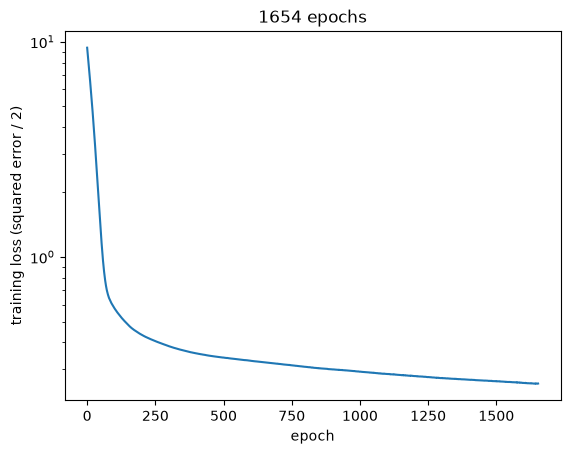

In [3]:
net = mlp[-1]
plt.plot(net.loss_curve_)
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("training loss (squared error / 2)")
plt.title(f"{net.n_iter_} epochs");

✏️ **Exercise A.1.** Compare the MLP with the random forest of session 1 using the same 5-fold
cross-validation (`cv` below). Which one wins?

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=RNG)
rf = RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)

r2_mlp = cross_val_score(mlp, X, y, cv=cv, scoring="r2")
r2_rf = cross_val_score(rf, X, y, cv=cv, scoring="r2")
print(f"MLP R2 = {r2_mlp.mean():.3f}   RF R2 = {r2_rf.mean():.3f}")

MLP R2 = 0.576   RF R2 = 0.604


### What function did each model learn?

The models live in 6 dimensions, so we cannot draw them. We can take a **slice**: vary `MLOGP` and
keep the other five descriptors fixed at their median. Each curve is the predicted LC50 along that slice.

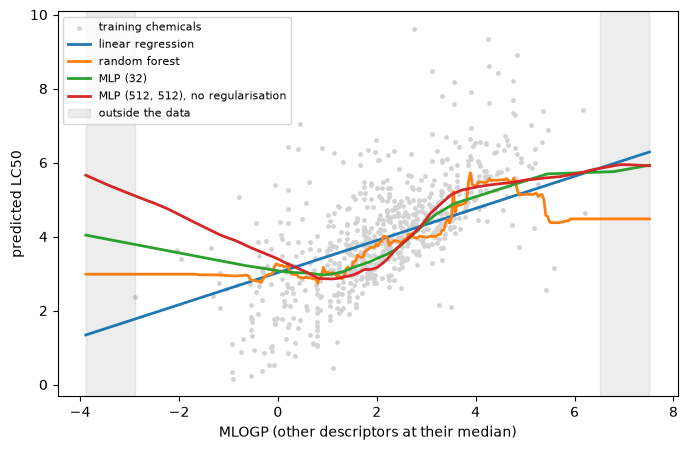

In [5]:
from sklearn.linear_model import LinearRegression

line = pd.DataFrame(np.tile(X_train.median().values, (300, 1)), columns=X.columns)
line["MLOGP"] = np.linspace(X["MLOGP"].min() - 1, X["MLOGP"].max() + 1, 300)

wide_mlp = make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(512, 512), alpha=1e-4,
                                      max_iter=2000, random_state=RNG))
fitted = {
    "linear regression": LinearRegression(),
    "random forest": RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1),
    "MLP (32)": mlp,                                   # already trained above
    "MLP (512, 512), no regularisation": wide_mlp,
}
plt.figure(figsize=(8, 5))
plt.scatter(X_train["MLOGP"], y_train, s=6, c="lightgrey", label="training chemicals")
for name, m in fitted.items():
    if m is not mlp:
        m.fit(X_train, y_train)
    plt.plot(line["MLOGP"], m.predict(line), lw=2, label=name)
plt.axvspan(line["MLOGP"].min(), X["MLOGP"].min(), color="k", alpha=0.07)
plt.axvspan(X["MLOGP"].max(), line["MLOGP"].max(), color="k", alpha=0.07, label="outside the data")
plt.xlabel("MLOGP (other descriptors at their median)"); plt.ylabel("predicted LC50")
plt.legend(fontsize=8);

❓ Describe the shape of each curve. What happens outside the range of the data (grey bands)?

**Answer.** Linear regression is a straight line everywhere. The random forest is a **staircase**:
each tree cuts the axis into intervals and predicts a constant in each, and beyond the data it goes
**flat** (it can never predict outside the range of the training LC50). The MLP is made of ReLUs,
so it is **piecewise linear**: smooth bends inside the data, then it continues as a straight line
outside, extrapolating in whatever direction the last piece pointed. Both MLPs bend **upwards** at low MLOGP,
predicting that very hydrophilic chemicals are *more* toxic: there are few training chemicals there,
the curve is not constrained, and the result is biologically implausible. The big unregularised
network bends more and has small wiggles where it follows individual chemicals: overfitting, seen directly.
None of the models can be trusted in the grey bands; QSAR guidelines call the region where a
model is valid its **applicability domain**.

### How big should the network be?

We train networks with two hidden layers of increasing width and compare the R² on the
**training** set with the R² on the **test** set.

,train R2,test R2
width,,
1,0.599,0.416
2,0.624,0.429
4,0.650,0.457
8,0.704,0.473
32,0.875,0.414
128,0.891,0.511
512,0.934,0.465


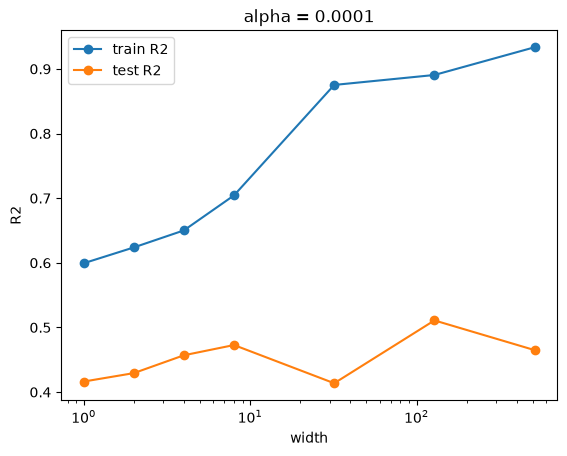

In [6]:
sizes = [1, 2, 4, 8, 32, 128, 512]

def size_sweep(alpha):
    """Train/test R2 for 2-hidden-layer MLPs of each width; alpha = L2 penalty on the weights."""
    rows = []
    for h in sizes:
        m = make_pipeline(StandardScaler(),
                          MLPRegressor(hidden_layer_sizes=(h, h), alpha=alpha,
                                       max_iter=2000, random_state=RNG))
        m.fit(X_train, y_train)
        rows.append((h, r2_score(y_train, m.predict(X_train)), r2_score(y_test, m.predict(X_test))))
    return pd.DataFrame(rows, columns=["width", "train R2", "test R2"]).set_index("width")

sweep = size_sweep(alpha=1e-4)          # almost no regularisation
sweep.plot(logx=True, marker="o")
plt.ylabel("R2"); plt.title("alpha = 0.0001");
sweep

❓ What happens to the gap between training and test R² as the network grows? What is this called?

✏️ **Exercise A.2.** `alpha` adds a penalty on large weights (*L2 regularisation*, "weight decay").
Run `size_sweep(alpha=1.0)` and compare with the plot above.

,train R2,test R2
width,,
1,0.590,0.412
2,0.623,0.430
4,0.653,0.464
8,0.704,0.497
32,0.784,0.524
128,0.800,0.553
512,0.773,0.559


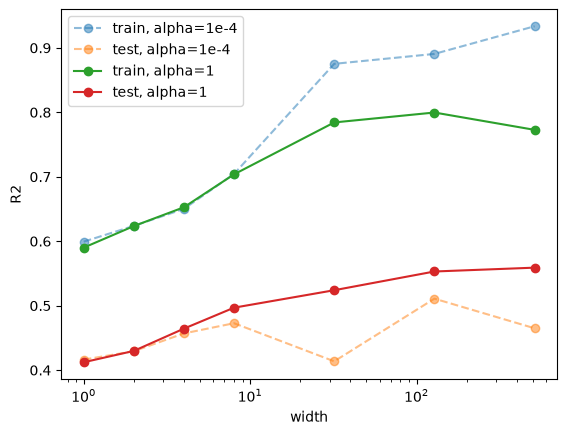

In [7]:
sweep_reg = size_sweep(alpha=1.0)
ax = sweep.plot(logx=True, marker="o", style="--", alpha=0.5)
sweep_reg.plot(logx=True, marker="o", ax=ax)
plt.legend(["train, alpha=1e-4", "test, alpha=1e-4", "train, alpha=1", "test, alpha=1"])
plt.ylabel("R2");
sweep_reg

**Answer.** Without regularisation, the bigger networks fit the training set better and better
(train R² up to ≈ 0.93) while the test R² does not improve: this is **overfitting** - the network
memorises the 681 training chemicals, noise included. With `alpha=1.0` the training R² stays
lower (≈ 0.8), the gap shrinks, and the large networks generalise best (test R² ≈ 0.55).
On a small table of 6 descriptors, an MLP does **not** beat a random forest (≈ 0.58 vs ≈ 0.60
in cross-validation). Neural networks shine with large data and with raw, structured inputs such as
sequences and images - which is where we go next.

### Overfitting, epoch by epoch

`loss_curve_` only shows the *training* loss, which always goes down. Let us train the big
(512, 512) network one epoch at a time (`partial_fit`) and measure the error on the test chemicals
after each epoch as well.

alpha=0.0001: best test MSE 0.855 at epoch 109, after 300 epochs train 0.140 / test 0.998


alpha=1: best test MSE 0.868 at epoch 286, after 300 epochs train 0.394 / test 0.869


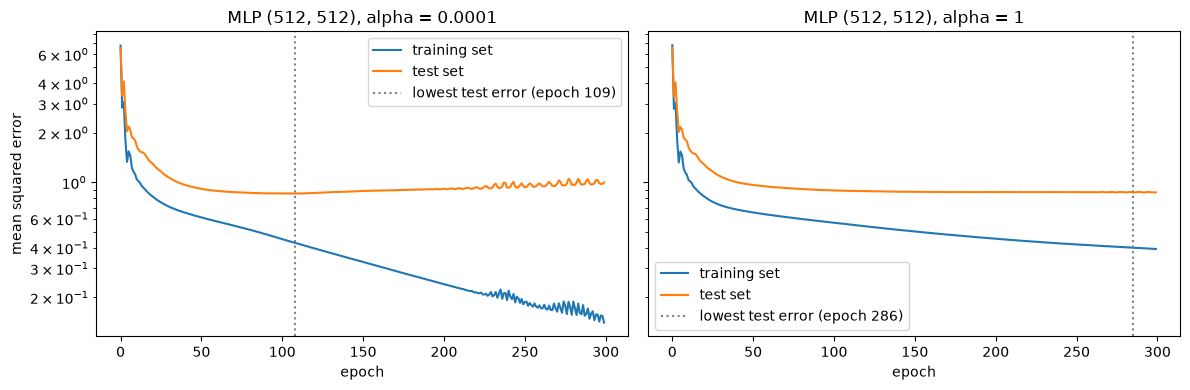

In [8]:
from sklearn.metrics import mean_squared_error

scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, alpha in zip(axes, [1e-4, 1.0]):
    net_e = MLPRegressor(hidden_layer_sizes=(512, 512), alpha=alpha, random_state=RNG)
    tr_mse, te_mse = [], []
    for epoch in range(300):
        net_e.partial_fit(Xtr_s, y_train)          # one more pass over the training data
        tr_mse.append(mean_squared_error(y_train, net_e.predict(Xtr_s)))
        te_mse.append(mean_squared_error(y_test, net_e.predict(Xte_s)))
    best = int(np.argmin(te_mse))
    ax.plot(tr_mse, label="training set")
    ax.plot(te_mse, label="test set")
    ax.axvline(best, color="grey", ls=":", label=f"lowest test error (epoch {best + 1})")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title(f"MLP (512, 512), alpha = {alpha:g}")
    print(f"alpha={alpha:g}: best test MSE {min(te_mse):.3f} at epoch {best + 1}, "
          f"after 300 epochs train {tr_mse[-1]:.3f} / test {te_mse[-1]:.3f}")
axes[0].set_ylabel("mean squared error"); axes[0].legend(); axes[1].legend()
plt.tight_layout()

❓ When should we have stopped training the unregularised network? What does regularisation change?

**Answer.** Without regularisation the training error keeps falling towards zero, while the test
error reaches its minimum (here around epoch 110, MSE ≈ 0.86) and then **climbs** again (≈ 1.0 after
300 epochs, while the training MSE is down to 0.14): from there on, every epoch spent memorising the training chemicals makes predictions on new ones worse. Stopping at the
minimum is called **early stopping**. Since we must not choose it by looking at the test set, it is
done on a validation set carved out of the training data (`MLPRegressor(early_stopping=True)`; we use
it for the enzyme classifier below). With `alpha = 1` the training error falls much more slowly and the test error
flattens out at ≈ 0.87 instead of rising: the penalty on large weights stops the network from memorising, whenever we stop.

### Playground: a neural network on a curve you can see

The same phenomena are much easier to *see* in one dimension. We use a toy problem where the true
curve is known: a few noisy "measurements" of a dose-response-like curve. `mlp_playground()` trains an
MLP on them one epoch at a time and draws:
* **left**: the network's curve at several moments during training (light = early, dark = late);
* **right**: training and test error at every epoch. The dotted line is the noise level (the error of
  the true curve itself): no model can do better than that on new data.

Parameters: `width` and `layers` (network size), `alpha` (L2 penalty), `n_train` (number of points),
`noise`, `epochs`, `seed`.

In [ ]:
def true_curve(x):
    """The 'truth' we pretend not to know: a smooth dose-response-like curve."""
    return 1 / (1 + np.exp(-10 * (x - 0.5))) + 0.3 * np.sin(6 * x)

def make_toy(n, noise, seed):
    """n noisy measurements of true_curve at random x in [0, 1]."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0, 1, n))
    return x, true_curve(x) + rng.normal(0, noise, n)

from sklearn.exceptions import ConvergenceWarning
import warnings

def mlp_playground(width=200, layers=2, alpha=1e-5, n_train=25, noise=0.2, epochs=3000, seed=0):
    x_tr, y_tr = make_toy(n_train, noise, seed)
    x_te, y_te = make_toy(500, noise, seed + 1000)
    grid = np.linspace(0, 1, 400)[:, None]
    net = MLPRegressor(hidden_layer_sizes=(width,) * layers, alpha=alpha,
                       learning_rate_init=0.003, random_state=seed)
    snap_epochs = sorted({int(e) for e in np.geomspace(10, epochs, 5)})
    tr_mse, te_mse, snaps = [], [], {}
    for epoch in range(1, epochs + 1):
        net.partial_fit(x_tr[:, None], y_tr)
        tr_mse.append(np.mean((net.predict(x_tr[:, None]) - y_tr) ** 2))
        te_mse.append(np.mean((net.predict(x_te[:, None]) - y_te) ** 2))
        if epoch in snap_epochs:
            snaps[epoch] = net.predict(grid)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    ax1.plot(grid, true_curve(grid), "k--", lw=1.5, label="true curve")
    for i, (e, curve) in enumerate(snaps.items()):
        ax1.plot(grid, curve, color=plt.cm.Reds(0.3 + 0.7 * i / max(1, len(snaps) - 1)), lw=2, label=f"epoch {e}")
    ax1.scatter(x_tr, y_tr, color="k", s=20, zorder=3, label=f"{n_train} training points")
    ax1.set_ylim(-1, 2); ax1.set_xlabel("dose"); ax1.set_ylabel("response"); ax1.legend(fontsize=7, loc="upper left")
    ax1.set_title(f"MLP {(width,) * layers}, alpha = {alpha:g}")

    best = int(np.argmin(te_mse))
    ax2.plot(range(1, epochs + 1), tr_mse, label="training points")
    ax2.plot(range(1, epochs + 1), te_mse, label="new points (test)")
    ax2.axhline(noise ** 2, color="grey", ls=":", label="noise level")
    ax2.axvline(best + 1, color="grey", alpha=0.5, label=f"best epoch ({best + 1})")
    ax2.set_xscale("log"); ax2.set_yscale("log"); ax2.set_xlabel("epoch"); ax2.set_ylabel("MSE")
    ax2.set_title(f"final: train {tr_mse[-1]:.3f}, test {te_mse[-1]:.3f} (best test {te_mse[best]:.3f})")
    ax2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

mlp_playground()
mlp_playground(alpha=0.1)

*Sliders:* in Jupyter or Colab with `ipywidgets` installed, the next cell shows sliders and redraws the figure when you release one. Without `ipywidgets`, just call the function with other values.

In [ ]:
try:
    from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider
    interact(mlp_playground,
             width=IntSlider(value=200, min=2, max=500, step=2, continuous_update=False),
             layers=IntSlider(value=2, min=1, max=4, continuous_update=False),
             alpha=FloatLogSlider(value=1e-5, base=10, min=-6, max=1, continuous_update=False),
             n_train=IntSlider(value=25, min=10, max=300, step=5, continuous_update=False),
             noise=FloatSlider(value=0.2, min=0.0, max=0.6, step=0.05, continuous_update=False),
             epochs=IntSlider(value=3000, min=100, max=6000, step=100, continuous_update=False),
             seed=IntSlider(value=0, min=0, max=20, continuous_update=False))
except ImportError:
    print("ipywidgets is not installed: call mlp_playground(width=..., alpha=..., n_train=...) instead")

✏️ **Exercise A.3.** Use the playground to answer:
1. In the first figure, in what order does the network learn things? When does the test error start
   to rise?
2. What changes with `alpha=0.1` (second figure)? And with `alpha=1`?
3. Without regularisation, which helps more against overfitting: a smaller network (`width=8`) or
   more data (`n_train=200`)?
4. Try `seed=1, 2, 3` with the default settings. Do you always get the same curve?

**Answer.**
1. First the **coarse trend** (the rise from low to high dose), then the S shape, and only at the end
   the details of individual points. Test error falls while the network learns real structure, reaches
   its minimum, and then rises as the curve starts bending towards individual noisy points. The
   training error keeps falling. Early stopping would keep the network from the best epoch.
2. With `alpha=0.1` the weights cannot grow large enough to make sharp bends: the final curve stays
   smooth, close to the true one, and the test error stays near its minimum however long we train.
   With `alpha=1` the penalty is too strong and the curve flattens: underfitting.
3. Both reduce overfitting. More data is the more reliable cure: with 200 points even a big network
   follows the true curve. A small network cannot memorise 25 points, but it can also miss real
   structure if it is too small.
4. No: different random initial weights (and a different sample of points) give different curves,
   especially between and outside the points. Neural networks are not unique solutions. Averaging
   several of them (an **ensemble**) is a common way to reduce this variance.

# Part B - Can we tell an enzyme's class from its sequence?

Enzymes are classified by the reaction they catalyse into **EC (Enzyme Commission) classes**:

| EC | class | reaction |
|---|---|---|
| 1 | Oxidoreductases | transfer of electrons (redox) |
| 2 | Transferases | transfer of a group (methyl, phosphate, ...) |
| 3 | Hydrolases | cleavage by water |
| 4 | Lyases | cleavage without water or oxidation |
| 5 | Isomerases | rearrangement within a molecule |
| 6 | Ligases | joining two molecules, using ATP |

Our dataset contains **2047 enzymes** from UniProt/Swiss-Prot (manually reviewed), from five model
organisms (human, *E. coli*, baker's yeast, *Arabidopsis*, *B. subtilis*), about 350 per class.
Each enzyme also has its **protein family** (groups of evolutionarily related proteins).

## B1 - Meet the data

In [9]:
enz = load_enzymes()
print(enz.shape)
enz.head()

(2047, 10)


,accession,entry_name,protein_name,organism,ec,ec_class,ec_name,family,length,sequence
0,A8MRX0,GSOX5_ARATH,Flavin-containing monooxygenase FMO GS-OX5,Arabidopsis thaliana,1.14.13.237,1,Oxidoreductase,FMO family,459,MAPARTRVNSLNVAVIGAGAAGLVAARELRRENHTVVVFERDSKVG...
1,A9X4U2,HSDD3_ARATH,3beta-hydroxysteroid-dehydrogenase/decarboxyla...,Arabidopsis thaliana,1.1.1.170,1,Oxidoreductase,3-beta-HSD family,561,MDEDSVHGDSHLKTCVVLGGRGFIGRSLVSRLLRLGNWTVRVADSG...
2,F4ILF8,P4H13_ARATH,Prolyl 4-hydroxylase 13,Arabidopsis thaliana,1.14.11.2,1,Oxidoreductase,P4HA family,274,MRSYGKEKKLVFPYVFIACCFFLAIFGFCFFNLFSQGISFSEIPTT...
3,F4K2M8,JMJ31_ARATH,Lysine-specific demethylase JMJ31,Arabidopsis thaliana,1.14.11.-,1,Oxidoreductase,JARID1 histone demethylase family,549,MPTGCEFPMIKTFENALTAADFESTVELTNFPAVFRGCASVWDAYS...
4,F4KAV2,AKB1D_ARATH,DNA N,Arabidopsis thaliana,1.14.11.51,1,Oxidoreductase,AlkB family,442,MLNSIHRSFHLTSRHQIVLRLCSPSASRTIMSSSPHSPIPKTHTAS...


In [10]:
print(enz["ec_name"].value_counts(), "\n")
pd.crosstab(enz["organism"], enz["ec_name"])

ec_name
Oxidoreductase    350
Transferase       350
Hydrolase         350
Lyase             350
Isomerase         350
Ligase            297
Name: count, dtype: int64 



ec_name,Hydrolase,Isomerase,Ligase,Lyase,Oxidoreductase,Transferase
organism,,,,,,
Arabidopsis thaliana,121,100,67,118,128,149
Bacillus subtilis,37,55,63,63,53,32
Escherichia coli,32,73,64,65,49,39
Homo sapiens,120,72,58,57,88,98
Saccharomyces cerevisiae,40,50,45,47,32,32


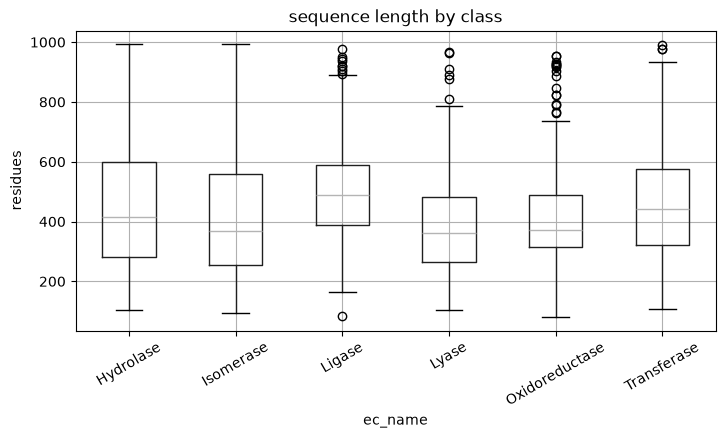

In [11]:
classes = sorted(enz["ec_name"].unique())
enz.boxplot(column="length", by="ec_name", figsize=(8, 4), rot=30)
plt.suptitle(""); plt.title("sequence length by class"); plt.ylabel("residues");

✏️ **Exercise B1.1.** Print one example sequence and its protein name. How many proteins come from
the largest protein family, and what is that family? *Hint:* `value_counts()` on `family`.

In [12]:
row = enz.iloc[0]
print(row["protein_name"], "|", row["organism"], "| EC", row["ec"])
print(row["sequence"])
print()
print(enz["family"].value_counts().head(5))

Flavin-containing monooxygenase FMO GS-OX5 | Arabidopsis thaliana | EC 1.14.13.237
MAPARTRVNSLNVAVIGAGAAGLVAARELRRENHTVVVFERDSKVGGLWVYTPNSEPDPLSLDPNRTIVHSSVYDSLRTNLPRECMGYRDFPFVPRPEDDESRDSRRYPSHREVLAYLEDFAREFKLVEMVRFKTEVVLVEPEDKKWRVQSKNSDGISKDEIFDAVVVCNGHYTEPRVAHVPGIDSWPGKQIHSHNYRVPDQFKDQVVVVIGNFASGADISRDITGVAKEVHIASRSNPSKTYSKLPGSNNLWLHSMIESVHEDGTIVFQNGKVVQADTIVHCTGYKYHFPFLNTNGYITVEDNCVGPLYEHVFPPALAPGLSFIGLPWMTLQFFMFELQSKWVAAALSGRVTLPSEEKMMEDVTAYYAKREAFGQPKRYTHRLGGGQVDYLNWIAEQIGAPPGEQWRYQEINGGYYRLATQSDTFRDKWDDDHLIVEAYEDFLRQKLISSLPSQLLES

family
FMO family                                                             8
NAD(P)-dependent epimerase/dehydratase family                          8
Peroxidase family, Classical plant (class III) peroxidase subfamily    8
Zinc-containing alcohol dehydrogenase family                           8
Aldehyde dehydrogenase family                                          8
Name: count, dtype: int64


## B2 - Amino-acid composition

The simplest way to turn a sequence of any length into a fixed-size vector: the **fraction of
each of the 20 amino acids**. This forgets the order completely.

In [13]:
comp = pd.DataFrame(np.vstack(enz["sequence"].map(aa_composition)), columns=list(AA))
comp.head()

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,0.063,0.009,0.063,0.070,0.044,0.065,0.033,0.044,0.044,0.072,0.017,0.041,0.061,0.035,0.065,0.072,0.044,0.096,0.020,0.044
1,0.062,0.016,0.059,0.043,0.078,0.066,0.023,0.053,0.053,0.109,0.014,0.030,0.027,0.025,0.050,0.103,0.048,0.087,0.016,0.036
2,0.055,0.022,0.051,0.066,0.084,0.066,0.026,0.051,0.062,0.077,0.015,0.044,0.047,0.040,0.047,0.077,0.058,0.051,0.011,0.051
3,0.077,0.016,0.062,0.077,0.049,0.044,0.038,0.044,0.049,0.111,0.029,0.044,0.044,0.031,0.046,0.106,0.038,0.055,0.015,0.027
4,0.034,0.016,0.054,0.061,0.041,0.063,0.032,0.063,0.057,0.084,0.020,0.048,0.059,0.036,0.075,0.124,0.059,0.052,0.007,0.016


Is any amino acid enriched in a class? We compare each class's mean composition with the overall
mean, on a $\log_2$ scale (+1 = twice as frequent).

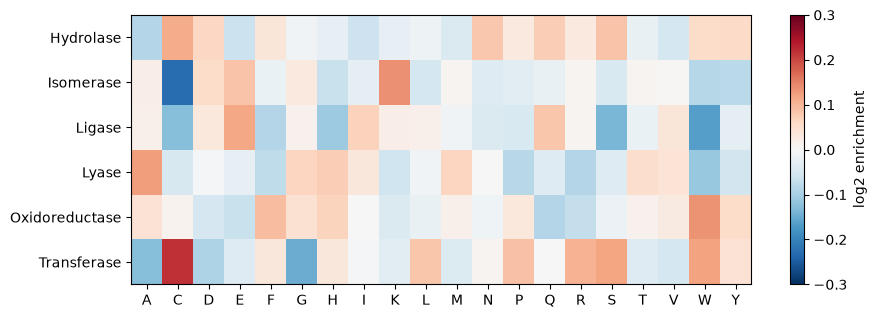

In [14]:
class_mean = comp.groupby(enz["ec_name"]).mean()
enrichment = np.log2(class_mean / comp.mean())

plt.figure(figsize=(10, 3.5))
plt.imshow(enrichment, cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
plt.colorbar(label="log2 enrichment")
plt.xticks(range(20), AA); plt.yticks(range(len(classes)), enrichment.index);

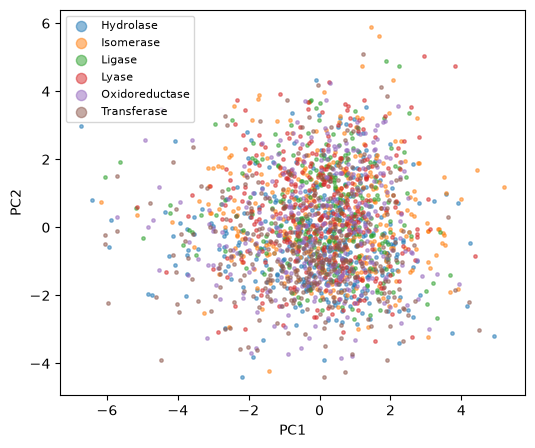

In [15]:
from sklearn.decomposition import PCA

Z = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(comp))
plt.figure(figsize=(6, 5))
for c in classes:
    sel = (enz["ec_name"] == c).values
    plt.scatter(Z[sel, 0], Z[sel, 1], s=6, alpha=0.5, label=c)
plt.legend(markerscale=3, fontsize=8); plt.xlabel("PC1"); plt.ylabel("PC2");

❓ How large are the differences in composition between classes? Do the classes separate in the
PCA map? What do you expect for a classifier?

**Answer.** The enrichments are tiny (within ±0.25 on a log2 scale, i.e. < 20%) and the classes
overlap completely in the PCA map. Composition carries only a faint signal about the catalysed
reaction: expect a classifier to do better than chance, but not much. (Some enrichments have a
story: Cys is enriched among transferases because ~15% of them transfer ubiquitin (EC 2.3.2.x,
e.g. RING-type E3 ligases), whose zinc-binding domains contain twice the average Cys.)

## B3 - Classifiers

Features: the 20 composition values plus log(length). We measure **accuracy** (fraction of
correct predictions) with stratified 5-fold cross-validation (each fold keeps the class
proportions). With 6 balanced classes, **random guessing gives about 1/6 = 0.17**.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

Xe = comp.assign(log_length=np.log(enz["length"]))
ye = enz["ec_name"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)

classifiers = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=RNG, n_jobs=-1),
    "MLP (64)": make_pipeline(StandardScaler(),
                              MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=True,
                                            max_iter=500, random_state=RNG)),
}
acc_random = {}
for name, clf in classifiers.items():
    acc_random[name] = cross_val_score(clf, Xe, ye, cv=skf, scoring="accuracy").mean()
    print(f"{name:20s} accuracy = {acc_random[name]:.3f}")

logistic regression  accuracy = 0.291


random forest        accuracy = 0.398


MLP (64)             accuracy = 0.294


Accuracy hides *which* classes get confused. A **confusion matrix** shows, for each true class (row),
how the predictions are distributed (columns). `cross_val_predict` gives one out-of-fold prediction
per enzyme.

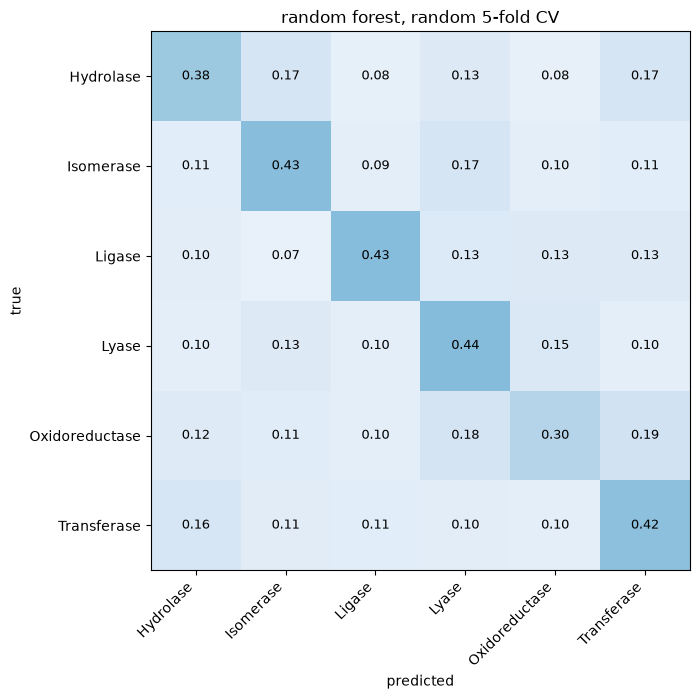

In [17]:
pred_rf = cross_val_predict(classifiers["random forest"], Xe, ye, cv=skf)
plot_confusion(ye, pred_rf, classes, title="random forest, random 5-fold CV");

❓ Which class is easiest to recognise, which is hardest? Any idea why?

**Answer.** Look at the diagonal: no class is easy (recall ≈ 0.30-0.45 each) and the errors
spread over all columns. Oxidoreductases are the hardest: a huge and chemically diverse class
(NAD-, FAD-, heme-, metal-dependent enzymes in many unrelated folds) with no common composition.
EC classes describe the *chemistry* of the reaction, which evolution has invented many times in
unrelated folds, so composition is a weak proxy for it.

## B4 - The homology trap

Proteins of the same **family** share a common ancestor and often have similar sequences - and
similar compositions. With a random split, a test enzyme usually has a close relative
(e.g. the same enzyme from another organism) in the training set, and the model can just
"recognise the family" instead of learning anything general.

A fairer test for a *new* kind of enzyme: keep **whole families** out of the training set.
`StratifiedGroupKFold` does this - all members of a group end up in the same fold.

In [18]:
from sklearn.model_selection import StratifiedGroupKFold

print(enz["family"].nunique(), "families;", (enz["family"].value_counts() > 1).sum(), "with more than one member")
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)
groups = enz["family"]

1102 families; 409 with more than one member


✏️ **Exercise B4.1.** Repeat the cross-validation of the three classifiers with `cv=sgkf` and
`groups=groups` (pass it as `cross_val_score(..., groups=groups)`), and print both accuracies
side by side.

In [19]:
for name, clf in classifiers.items():
    acc_family = cross_val_score(clf, Xe, ye, cv=sgkf, groups=groups, scoring="accuracy").mean()
    print(f"{name:20s} random split = {acc_random[name]:.3f}   family split = {acc_family:.3f}")

logistic regression  random split = 0.291   family split = 0.270


random forest        random split = 0.398   family split = 0.306


MLP (64)             random split = 0.294   family split = 0.265


❓ Which model loses the most when families are held out, and why? Which number would you report
in a paper claiming "our model predicts the class of newly discovered enzymes"?

**Answer.** The random forest drops the most (≈ 0.40 → 0.30): it is the most flexible model and
partly works as a "find the relative" lookup table. Logistic regression and the MLP drop less
because they were learning less family-specific detail in the first place. For new enzymes, the
family-split number is the honest one. The random-split number answers a different question
("can I annotate a new member of a family I already know?") - for which a BLAST search against
annotated sequences would beat all of these models.

Where exactly does the inflated random-split accuracy come from? For each enzyme, count how many
members of its family were in the **training folds** when it was predicted (in the random 5-fold CV
of B3), and compare the accuracy of the random forest across these groups.

                        mean  size
relatives in training             
0                      0.325   781
1                      0.351   441
2-3                    0.434   429
4+                     0.553   396


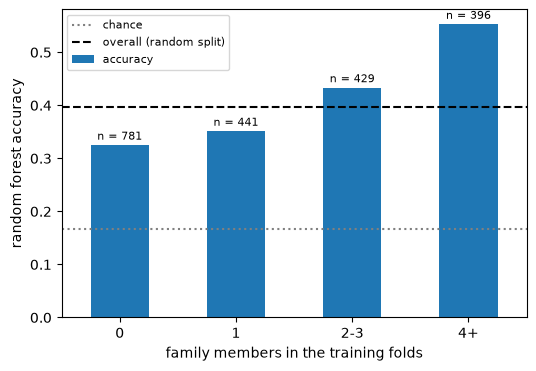

In [20]:
fold = np.zeros(len(enz), dtype=int)
for i, (_, test_idx) in enumerate(skf.split(Xe, ye)):
    fold[test_idx] = i
fam = enz["family"].fillna("").values
n_relatives = np.array([0 if fam[j] == "" else ((fam == fam[j]) & (fold != fold[j])).sum()
                        for j in range(len(enz))])
correct = (pred_rf == ye.values)

bins = pd.cut(n_relatives, [-1, 0, 1, 3, 100], labels=["0", "1", "2-3", "4+"])
by_rel = pd.DataFrame({"relatives in training": bins, "correct": correct}) \
           .groupby("relatives in training", observed=True)["correct"].agg(["mean", "size"])
print(by_rel)

ax = by_rel["mean"].plot.bar(rot=0, color="tab:blue", figsize=(6, 4), label="accuracy")
for i, (acc, n) in enumerate(zip(by_rel["mean"], by_rel["size"])):
    ax.text(i, acc + 0.01, f"n = {n}", ha="center", fontsize=8)
ax.axhline(1 / 6, color="grey", ls=":", label="chance")
ax.axhline(acc_random["random forest"], color="k", ls="--", label="overall (random split)")
ax.set_ylabel("random forest accuracy"); ax.set_xlabel("family members in the training folds")
ax.legend(fontsize=8);

❓ What does this plot say about the random-split accuracy?

**Answer.** Accuracy grows with the number of relatives in the training set. Enzymes with no relative
in training get ≈ 0.33, close to the family-split number (≈ 0.31), while those with 4 or more
relatives get ≈ 0.55: the random forest is largely recognising the family.
The random-split accuracy is an average over these groups, so it depends on how many relatives the
dataset happens to contain, not only on how good the model is.

## Summary

* An MLP is a flexible function approximator; on a small table it overfits easily, needs scaled
  inputs and regularisation, and does not beat a random forest. Watching the **test loss epoch by
  epoch** shows when it starts memorising (early stopping).
* **Data mining before modelling** told us what to expect: the enzyme classes barely differ in
  composition, and models got 0.25-0.40 accuracy (chance: 0.17).
* **How you split matters as much as which model you use.** Related sequences across the
  train/test boundary inflate the scores; split by family (or by sequence identity) to estimate
  performance on genuinely new proteins.
* Composition throws away the **order** of the residues. Next session: a neural network that reads
  the sequence residue by residue.

### If you have time

✏️ Replace composition by **dipeptide** frequencies (400 features: AA, AC, ..., YY) and redo the
random vs family comparison for the random forest. Does the gap grow or shrink?

In [21]:
import itertools
DIPEPTIDES = ["".join(p) for p in itertools.product(AA, repeat=2)]
index = {dp: i for i, dp in enumerate(DIPEPTIDES)}

def dipeptide_composition(seq):
    v = np.zeros(len(DIPEPTIDES))
    for i in range(len(seq) - 1):
        v[index[seq[i:i + 2]]] += 1
    return v / (len(seq) - 1)

Xd = np.vstack(enz["sequence"].map(dipeptide_composition))
rf = classifiers["random forest"]
print(f"random split: {cross_val_score(rf, Xd, ye, cv=skf).mean():.3f}")
print(f"family split: {cross_val_score(rf, Xd, ye, cv=sgkf, groups=groups).mean():.3f}")

random split: 0.376


family split: 0.283


**Answer.** Dipeptides do not help (≈ 0.38 random, ≈ 0.28 family split, vs 0.40 / 0.31 with
composition): 400 noisy features for 2047 proteins is a lot, and the leakage gap stays ≈ 0.09.
More features is not the same as more information.